Q1. Histogram Equalization


Histogram equalization is a technique used to improve the contrast of a grayscale image.
- A dark image may have most pixel intensities near 0.
- A bright image may have most intensities near 255.
- Histogram equalization spreads the intensity values across a wider range, making details easier to see.
For an 8-bit grayscale image, pixel intensities range from 0 to 255.

The main steps are:
1. Calculate the histogram (frequency of each intensity).
2. Calculate the cumulative histogram.
3. Normalize the cumulative values to get a mapping from old intensities to new intensities.
4. Replace each pixel with its new intensity.
5. Display the original and equalized images.


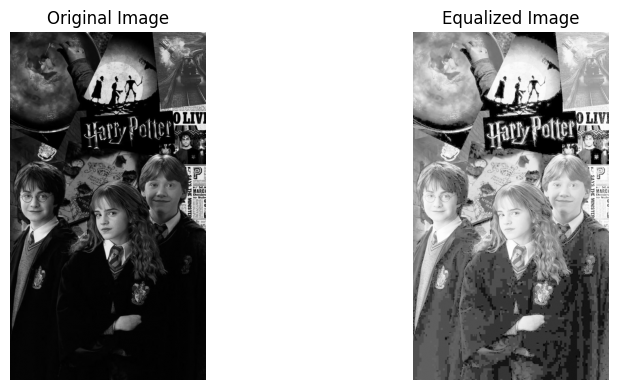

In [2]:
# python code without open cv

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read the grayscale image
img = Image.open("abc.jpg").convert("L")
img = np.array(img)

# Step 1: Calculate histogram
hist = np.zeros(256, dtype=int)

for pixel in img.flatten():
    hist[pixel] += 1

# Step 2: Calculate cumulative histogram
cdf = np.cumsum(hist)

# Step 3: Normalize CDF
cdf_min = cdf[cdf > 0][0]
total_pixels = img.size

mapping = np.round(
    (cdf - cdf_min) / (total_pixels - cdf_min) * 255
).clip(0, 255).astype(np.uint8)

# Step 4: Map old intensities to new intensities
equalized_img = mapping[img]

# Step 5: Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

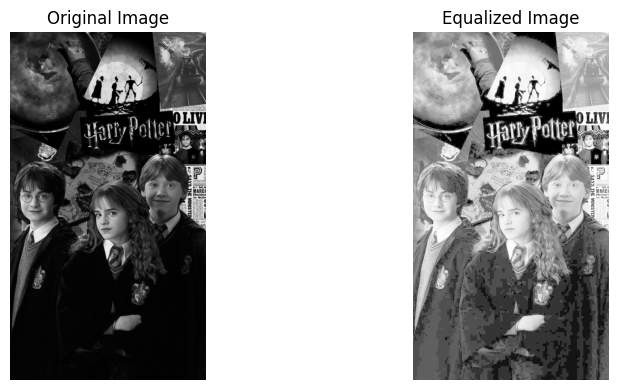

In [3]:
# OpenCV code

import cv2
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Image not found. Check the file path.")

# Perform histogram equalization
equalized_img = cv2.equalizeHist(img)

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Q2. Histogram Matching
Concept
Histogram matching, also called histogram specification, means changing the intensity distribution of an input image so that it resembles the distribution of a reference image.

For example, suppose:
- Input image: A dark image.
- Reference image: A brighter image.
- Output image: The input image adjusted to have a similar intensity distribution to the reference.

The main steps are:
1. Read the input and reference images in grayscale.
2. Calculate the histogram of each image.
3. Calculate the normalized cumulative distribution function (CDF) of each image.
4. For each input intensity, find the reference intensity with the closest CDF value.
5. Replace input pixels using this mapping and display the result.

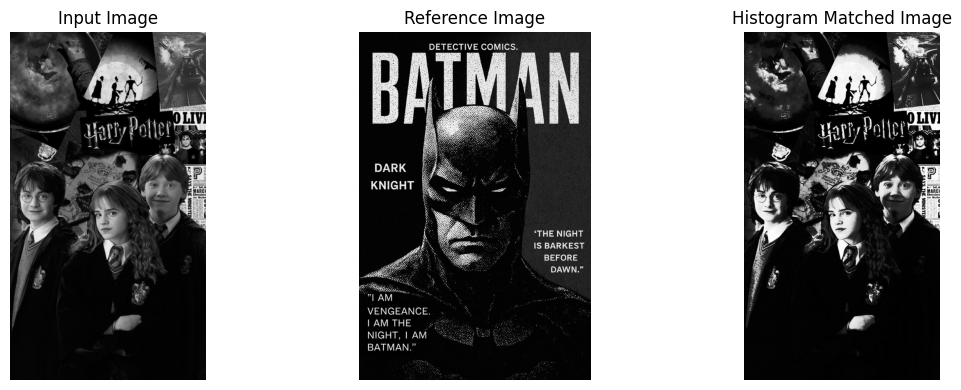

In [5]:
# Python code — without OpenCV

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read both images in grayscale
input_img = np.array(
    Image.open("abc.jpg").convert("L")
)
reference_img = np.array(
    Image.open("xyz.jpg").convert("L")
)

# Step 1: Calculate histograms
hist_input = np.bincount(input_img.ravel(), minlength=256)
hist_ref = np.bincount(reference_img.ravel(), minlength=256)

# Step 2: Calculate normalized CDFs
cdf_input = np.cumsum(hist_input) / input_img.size
cdf_ref = np.cumsum(hist_ref) / reference_img.size

# Step 3: Create intensity mapping
mapping = np.zeros(256, dtype=np.uint8)

for intensity in range(256):
    difference = np.abs(cdf_ref - cdf_input[intensity])
    mapping[intensity] = np.argmin(difference)

# Step 4: Apply mapping to input image
matched_img = mapping[input_img]

# Step 5: Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_img, cmap="gray", vmin=0, vmax=255)
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram Matched Image")
plt.axis("off")

plt.tight_layout()
plt.show()


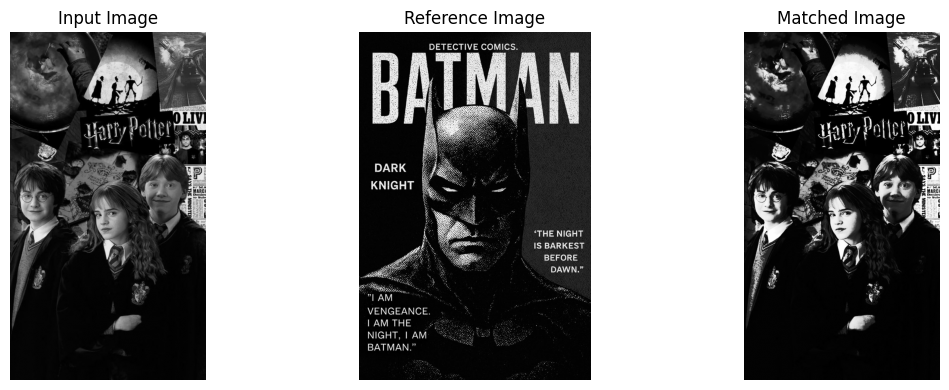

In [6]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images
input_img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)
reference_img = cv2.imread(
    "xyz.jpg", cv2.IMREAD_GRAYSCALE
)

if input_img is None or reference_img is None:
    raise FileNotFoundError("Check the image file paths.")

# Step 1: Calculate histograms
hist_input = cv2.calcHist(
    [input_img], [0], None, [256], [0, 256]
).flatten()

hist_ref = cv2.calcHist(
    [reference_img], [0], None, [256], [0, 256]
).flatten()

# Step 2: Calculate normalized CDFs
cdf_input = np.cumsum(hist_input) / input_img.size
cdf_ref = np.cumsum(hist_ref) / reference_img.size

# Step 3: Create mapping
mapping = np.zeros(256, dtype=np.uint8)

for intensity in range(256):
    difference = np.abs(cdf_ref - cdf_input[intensity])
    mapping[intensity] = np.argmin(difference)

# Step 4: Apply mapping
matched_img = cv2.LUT(input_img, mapping)

# Step 5: Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_img, cmap="gray", vmin=0, vmax=255)
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap="gray", vmin=0, vmax=255)
plt.title("Matched Image")
plt.axis("off")

plt.tight_layout()
plt.show()